In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Positional Bias — Molmo2-4B across Kvasir-SEG, ISIC 2018, and LGG (50 images each)

Runs **Molmo2-4B** (`allenai/Molmo2-4B`) zero-shot on 50 sampled images x 5 positional prompts (P0-P4)
from `position_bias_research_plan.md` per dataset, and scores its answers against the ground truth
already computed in each dataset's `manifest_<name>.csv`.

**Scope of this run**
- Datasets: Kvasir-SEG (colon polyps), ISIC 2018 (skin lesions), LGG Segmentation (brain tumors) —
  50 images x 5 prompts = 250 rows each
- Model: Molmo2-4B (Qwen3-4B-Instruct backbone + SigLIP 2 vision encoder), zero-shot, no fine-tuning,
  loaded **once** and reused across all 3 datasets. Chosen over the 8B/7B siblings for speed/memory
  while scoring almost identically on Ai2's own 15-benchmark average (62.8 vs 8B's 63.1)
- **Point tier**: per the plan, Molmo2 outputs a single (x, y) point, not a box or mask — its native
  output format is a `<points ... coords="idx x y"/>` XML-ish tag with coordinates normalized 0-1000
  relative to the **original** image dimensions (this holds regardless of any internal/manual
  resizing done for speed, per the model card's own decode step), so we reuse the model card's own
  regex-based parser unchanged
- We append one **fixed, content-neutral instruction** ("Point to it.") after `prompt_text`, identical
  across all 5 prompts, to reliably trigger Molmo2's structured pointing output (its point-tag format
  is trained around "point to X"-style phrasing) — this never becomes a second confounding variable
  alongside the P0-P4 positional wording
- **Speed**: we cap every image to a fixed visual-token budget (`PIXEL_BUDGET`, ~224x224) before
  encoding, passed to the processor via `min_pixels`/`max_pixels` if it accepts them, and always
  additionally enforced by resizing the image ourselves first (belt-and-suspenders, since Molmo2's
  SigLIP2-based processor isn't guaranteed to expose the same Qwen2-VL-style resize knobs)

**What this notebook produces, per dataset `<name>` in `{kvasir, isic, lgg}`**
- `results_<name>_molmo2/<name>_molmo2_results.csv` — the manifest plus new prediction/scoring columns
  appended after `prompt_text`
- `results_<name>_molmo2/visualizations/<sample_id>.png` — one figure per image, all 5 prompts side by
  side, showing ground truth (red) vs. Molmo2's parsed point (green)
- `results_<name>_molmo2/<name>_molmo2_summary_by_prompt.csv` — aggregated wrong-side rate / distance
  by prompt
- Inline plots in this notebook for a handful of examples plus the summary charts, per dataset

## How to run this in Google Colab

1. Upload the entire `run_colab/` folder (this notebook + `data/kvasir/`, `data/isic/`, `data/lgg/`)
   into your Colab session, or mount Google Drive and place it there (this notebook mounts Drive at
   `/content/drive` and expects the folder at `/content/drive/MyDrive/run_colab`).
2. `Runtime > Change runtime type > T4 GPU` is sufficient — Molmo2-4B is small enough to fit without
   quantization.
3. Run all cells top to bottom. **No Hugging Face token is needed** — `allenai/Molmo2-4B` is a public,
   non-gated model.
4. This is a chat model doing full text generation per row (not a single forward pass like OWLv2), so
   it's slower than OWLv2 but should be considerably faster than the Qwen2.5-VL notebooks thanks to
   the small `PIXEL_BUDGET`.
5. Just run every cell top to bottom, in order, on a fresh runtime -- there is no manual setup step
   and nothing needs to have been run before; the final loop cell processes Kvasir-SEG, ISIC 2018, and
   LGG one after another using the functions defined earlier in the notebook.

In [2]:
%pip install -q "transformers==4.57.1" "accelerate==1.10.1" einops torchvision decord2 molmo_utils pillow pandas matplotlib tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 109.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.9/374.9 kB 35.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.6/26.6 MB 41.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 118.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.8/35.8 MB 26.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [3]:
from pathlib import Path

IN_COLAB = "google.colab" in str(get_ipython())

if IN_COLAB:
    ROOT = Path("/content/drive/MyDrive/run_colab")
    if not ROOT.exists():
        raise FileNotFoundError(
            "Upload the whole 'run_colab' folder into /content (e.g. drag it into the Colab file "
            "browser on the left, or mount Drive and copy it there) before running this cell."
        )
else:
    ROOT = Path.cwd()
    if ROOT.name != "run_colab":
        candidate = ROOT / "run_colab"
        ROOT = candidate if candidate.exists() else ROOT

print(f"ROOT = {ROOT}")


def get_dataset_paths(dataset_name, results_folder):
    """Return (data_dir, out_dir, vis_dir) for one dataset, creating the output dirs."""
    data_dir = ROOT / "data" / dataset_name
    out_dir = ROOT / results_folder
    vis_dir = out_dir / "visualizations"
    out_dir.mkdir(parents=True, exist_ok=True)
    vis_dir.mkdir(parents=True, exist_ok=True)
    return data_dir, out_dir, vis_dir

ROOT = /content/drive/MyDrive/run_colab


In [4]:
import pandas as pd


def load_manifest(dataset_name, data_dir):
    manifest = pd.read_csv(data_dir / f"manifest_{dataset_name}.csv")
    assert len(manifest) == 250, f"{dataset_name}: expected 250 rows (50 images x 5 prompts), got {len(manifest)}"
    assert manifest["sample_id"].nunique() == 50, f"{dataset_name}: expected 50 unique images"
    print(f"[ok] {dataset_name}: loaded manifest with {len(manifest)} rows, {manifest['sample_id'].nunique()} images")
    return manifest

In [5]:
import torch
from transformers import AutoModelForImageTextToText, AutoProcessor

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    print("[warn] No GPU detected. Molmo2-4B will be slow on CPU. In Colab: Runtime > Change runtime type > GPU.")

MODEL_NAME = "allenai/Molmo2-4B"

# Determine the appropriate dtype for loading the model to save VRAM
if torch.cuda.is_available() and torch.cuda.is_bf16_supported():
    torch_dtype = torch.bfloat16
    print("[info] Using bfloat16 for model loading due to GPU support.")
elif torch.cuda.is_available():
    torch_dtype = torch.float16
    print("[info] Using float16 for model loading.")
else:
    torch_dtype = torch.float32 # Default for CPU or if neither bfloat16/float16 is chosen
    print("[info] Using float32 for model loading (no specific FP16/BF16 support detected or on CPU).")


# NOTE: deliberately NOT using device_map="auto" here -- with this custom (trust_remote_code)
# architecture it can leave some submodules on the "meta" device (a lazy-loading placeholder with
# no real data), which crashes every generate() call with "Cannot copy out of meta tensor; no data!".
# Loading normally then moving the whole model with .to(device) avoids that dispatch path entirely.
model = AutoModelForImageTextToText.from_pretrained(MODEL_NAME, trust_remote_code=True, torch_dtype=torch_dtype)
model = model.to(DEVICE)
model.eval()

# Fixed visual-token budget: 64 * 28 * 28 = ~50k pixels (~224x224).
# This keeps encoding fast and consistent across all images.
PIXEL_BUDGET = 64 * 28 * 28

try:
    processor = AutoProcessor.from_pretrained(
        MODEL_NAME,
        trust_remote_code=True,
        # dtype is typically not needed for processors as they primarily handle tokenization and image transformations, not model weights.
        min_pixels=PIXEL_BUDGET,
        max_pixels=PIXEL_BUDGET,
    )
except TypeError:
    # this processor doesn't accept min_pixels/max_pixels -- we still resize images ourselves
    # below (resize_for_speed), so the pixel budget is enforced either way.
    processor = AutoProcessor.from_pretrained(MODEL_NAME, trust_remote_code=True)

print(f"[ok] loaded {MODEL_NAME} on {DEVICE} (pixel_budget={PIXEL_BUDGET})")

[info] Using bfloat16 for model loading due to GPU support.


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

configuration_molmo2.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/allenai/Molmo2-4B:
- configuration_molmo2.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
`torch_dtype` is deprecated! Use `dtype` instead!


...

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.5M [00:00<?, ?B/s]

added_tokens.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

[ok] loaded allenai/Molmo2-4B on cuda (pixel_budget=50176)


## Run inference

For each of the 250 (image, prompt) rows, we build a single-turn chat message (`prompt_text` + a
fixed "Point to it." instruction, then the image) exactly as documented on the model card's
Multi-Image Point QA example, then parse Molmo2's `<points coords="idx x y"/>` output using the same
regex helpers from that example. Coordinates are normalized 0-1000 relative to the image's **original**
dimensions (passed to the parser regardless of any resizing done before encoding), so we convert
directly to this image's own pixel space to compare against the manifest's ground truth
(`gt_centroid_x/y`). Responses with no parseable point are recorded as no-detection (NaN).

In [6]:
import math
import re

import numpy as np
from PIL import Image
from tqdm.auto import tqdm

GROUNDING_SUFFIX = " Point to it."

# --- regex helpers, copied unchanged from the model card's Multi-Image Point QA example ---
COORD_REGEX = re.compile(r'<(?:points|tracks).*? coords="([0-9\t:;, .]+)"/?>')
FRAME_REGEX = re.compile(r"(?:^|\t|:|,|;)([0-9\.]+) ([0-9\. ]+)")
POINTS_REGEX = re.compile(r"([0-9]+) ([0-9]{3,4}) ([0-9]{3,4})")


def _points_from_num_str(text, image_w, image_h, extract_ids=False):
    for points in POINTS_REGEX.finditer(text):
        ix, x, y = points.group(1), points.group(2), points.group(3)
        # points format assumes coordinates are scaled by 1000
        x, y = float(x) / 1000 * image_w, float(y) / 1000 * image_h
        if 0 <= x <= image_w and 0 <= y <= image_h:
            yield ix, x, y


def extract_multi_image_points(text, image_w, image_h, extract_ids=False):
    """Extract pointing coordinates as a flattened list of (frame_id, x, y) triplets from model output text."""
    all_points = []
    diff_res = isinstance(image_w, (list, tuple)) and isinstance(image_h, (list, tuple))
    for coord in COORD_REGEX.finditer(text):
        for point_grp in FRAME_REGEX.finditer(coord.group(1)):
            frame_id = int(point_grp.group(1)) if diff_res else float(point_grp.group(1))
            w, h = (image_w[frame_id - 1], image_h[frame_id - 1]) if diff_res else (image_w, image_h)
            for idx, x, y in _points_from_num_str(point_grp.group(2), w, h):
                all_points.append((frame_id, idx, x, y) if extract_ids else (frame_id, x, y))
    return all_points
# --- end model-card helpers ---


def resize_for_speed(image, pixel_budget=PIXEL_BUDGET):
    """Downscale (never upscale) so width*height <= pixel_budget, preserving aspect ratio -- a
    guaranteed speed floor regardless of whether the processor itself honors min/max_pixels."""
    w, h = image.size
    if w * h <= pixel_budget:
        return image
    scale = math.sqrt(pixel_budget / (w * h))
    return image.resize((max(1, int(w * scale)), max(1, int(h * scale))))


# Fallback: the classic single <point x="51.2" y="68.3" alt="...">...</point> tag Molmo/Molmo2 can
# emit for a single plain image (as opposed to the multi-image/video coords= tag above). Its x/y are
# a 0-100 PERCENT scale, not the 0-1000 scale used by coords=, so it needs its own conversion.
SINGLE_POINT_REGEX = re.compile(r'<point[^>]*?\bx="([\d.]+)"[^>]*?\by="([\d.]+)"')


def parse_molmo_point(text, width, height):
    """Try the coords="idx x y" (0-1000) tag first, then fall back to <point x=.. y=..> (0-100)."""
    points = extract_multi_image_points(text, [width], [height])
    if points:
        _, x, y = points[0]
        return (x, y)
    match = SINGLE_POINT_REGEX.search(text)
    if match:
        x_pct, y_pct = float(match.group(1)), float(match.group(2))
        return (x_pct / 100 * width, y_pct / 100 * height)
    return None


def build_molmo_messages(image, text):
    return [{
        "role": "user",
        "content": [
            dict(type="text", text=text + GROUNDING_SUFFIX),
            dict(type="image", image=image),
        ],
    }]


def run_molmo_detect(model, processor, device, image, text, max_new_tokens=256):
    """Return ((x, y) in the ORIGINAL image's pixels, or None, raw generated text)."""
    orig_w, orig_h = image.size
    model_image = resize_for_speed(image)
    messages = build_molmo_messages(model_image, text)

    inputs = processor.apply_chat_template(
        messages, tokenize=True, add_generation_prompt=True, return_tensors="pt", return_dict=True,
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.inference_mode():
        generated_ids = model.generate(**inputs, max_new_tokens=max_new_tokens)
    generated_tokens = generated_ids[0, inputs["input_ids"].size(1):]
    output_text = processor.tokenizer.decode(generated_tokens, skip_special_tokens=True)

    point = parse_molmo_point(output_text, orig_w, orig_h)
    return point, output_text


def run_molmo_inference(model, processor, device, manifest_df, data_dir, desc="Molmo2 inference"):
    """Call Molmo2 for every row; returns a new df with molmo_x/y/raw_text columns."""
    df = manifest_df.copy()
    x_list, y_list, raw_list = [], [], []

    for _, row in tqdm(df.iterrows(), total=len(df), desc=desc):
        image = Image.open(data_dir / row["image_path"]).convert("RGB")

        try:
            point, raw_text = run_molmo_detect(model, processor, device, image, row["prompt_text"])
        except Exception as e:  # keep the run alive if one row errors out
            point, raw_text = None, f"[error] {e}"

        if point is not None:
            x_list.append(point[0]); y_list.append(point[1])
        else:
            x_list.append(np.nan); y_list.append(np.nan)
        raw_list.append(raw_text)

    df["molmo_x"] = x_list
    df["molmo_y"] = y_list
    df["molmo_raw_text"] = raw_list

    n_failed = df["molmo_x"].isna().sum()
    print(f"[ok] ran inference on {len(df)} rows ({n_failed} rows failed to parse a point)")
    if n_failed:
        sample = df.loc[df["molmo_x"].isna(), "molmo_raw_text"].head(3).tolist()
        print("[debug] raw text from up to 3 failed rows, to check the actual output format:")
        for i, t in enumerate(sample):
            print(f"  [{i}] {t!r}")
    return df

## Score predictions against ground truth

Adds, per row: predicted side (left/right, upper/lower), whether that matches the *prompted* direction
(RQ1/RQ3), whether the prompted direction actually matched this image's true ground-truth side (needed
to split rows for RQ2 vs RQ3), normalized distance to `gt_centroid_x/y`, and the shift from this same
image's own P0 answer (RQ1's "did it move at all?"). No IoU here -- Molmo2 is point-tier, there's no
box to overlap.

In [7]:
from PIL import Image as PILImage


def side_lr(x, width):
    return "left" if x < width / 2 else "right"


def side_ud(y, height):
    return "upper" if y < height / 2 else "lower"


PROMPT_AXIS = {
    "P0": (None, None),
    "P1": ("lr", "left"),
    "P2": ("lr", "right"),
    "P3": ("ud", "upper"),
    "P4": ("ud", "lower"),
}


def correct_side(row, side_lr_col, side_ud_col):
    # Returns 1.0/0.0 (not bool) and NaN (not None) so the column stays numeric for mean(numeric_only=True).
    if row["prompted_axis"] == "lr" and row[side_lr_col] is not None:
        return float(row[side_lr_col] == row["prompted_direction"])
    if row["prompted_axis"] == "ud" and row[side_ud_col] is not None:
        return float(row[side_ud_col] == row["prompted_direction"])
    return np.nan  # P0 has no prompted direction to compare against


def prompt_matches_gt(row):
    """Model-independent: does the prompted direction match this image's real ground truth side?"""
    if row["prompted_axis"] == "lr":
        return row["prompted_direction"] == row["gt_side_lr"]
    if row["prompted_axis"] == "ud":
        return row["prompted_direction"] == row["gt_side_ud"]
    return None


def norm_dist(px, py, row):
    if pd.isna(px):
        return np.nan
    diag = np.hypot(row["img_width"], row["img_height"])
    return np.hypot(px - row["gt_centroid_x"], py - row["gt_centroid_y"]) / diag


def no_shift(row, shift_col):
    """1.0 if the answer moved less than 5% of the image diagonal from its own P0 answer, else 0.0, NaN if not applicable."""
    if row["prompt_id"] == "P0" or pd.isna(row[shift_col]):
        return np.nan
    diag = np.hypot(row["img_width"], row["img_height"])
    return float(row[shift_col] < 0.05 * diag)


def score_predictions(df, data_dir):
    """Add every derived scoring column: side labels, correct-side, normalized distance, shift-from-P0."""
    df = df.copy()

    sizes = {p: PILImage.open(data_dir / p).size for p in df["image_path"].unique()}
    df["img_width"] = df["image_path"].map(lambda p: sizes[p][0])
    df["img_height"] = df["image_path"].map(lambda p: sizes[p][1])

    df["molmo_side_lr"] = df.apply(lambda r: side_lr(r["molmo_x"], r["img_width"]) if pd.notna(r["molmo_x"]) else None, axis=1)
    df["molmo_side_ud"] = df.apply(lambda r: side_ud(r["molmo_y"], r["img_height"]) if pd.notna(r["molmo_y"]) else None, axis=1)

    df["prompted_axis"] = df["prompt_id"].map(lambda p: PROMPT_AXIS[p][0])
    df["prompted_direction"] = df["prompt_id"].map(lambda p: PROMPT_AXIS[p][1])

    df["molmo_correct_side"] = df.apply(lambda r: correct_side(r, "molmo_side_lr", "molmo_side_ud"), axis=1)
    df["prompt_matches_gt"] = df.apply(prompt_matches_gt, axis=1)

    df["molmo_dist_norm"] = df.apply(lambda r: norm_dist(r["molmo_x"], r["molmo_y"], r), axis=1)

    p0_lookup = df[df["prompt_id"] == "P0"].set_index("sample_id")

    def shift_from_p0(row, x_col, y_col):
        if row["sample_id"] not in p0_lookup.index or pd.isna(row[x_col]):
            return np.nan
        p0x, p0y = p0_lookup.loc[row["sample_id"], x_col], p0_lookup.loc[row["sample_id"], y_col]
        if pd.isna(p0x):
            return np.nan
        return np.hypot(row[x_col] - p0x, row[y_col] - p0y)

    df["molmo_shift_from_p0"] = df.apply(lambda r: shift_from_p0(r, "molmo_x", "molmo_y"), axis=1)
    df["molmo_no_shift"] = df.apply(lambda r: no_shift(r, "molmo_shift_from_p0"), axis=1)

    print("[ok] derived scoring columns computed")
    return df

In [8]:
def save_results(df, out_dir, dataset_name):
    results_csv = out_dir / f"{dataset_name}_molmo2_results.csv"
    df.to_csv(results_csv, index=False)
    print(f"[ok] wrote {len(df)} rows x {len(df.columns)} columns -> {results_csv}")
    return results_csv

## Visualize: ground truth vs. Molmo2's predictions

One figure per image, 5 panels (P0-P4): red = ground truth (box + centroid), green = Molmo2's parsed
point. Yellow lines mark the image's true midline/midheight, same convention as
`scripts/visualize_ground_truth.py`. All 50 are saved to disk; the first 2 are also shown inline here.

In [9]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt

PROMPT_LABELS = {"P0": "P0 (neutral)", "P1": "P1 (left)", "P2": "P2 (right)", "P3": "P3 (upper)", "P4": "P4 (lower)"}


def plot_sample(df, data_dir, vis_dir, sample_id, save=True, show=False):
    rows = df[df["sample_id"] == sample_id].set_index("prompt_id")
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    for ax, prompt_id in zip(axes, ["P0", "P1", "P2", "P3", "P4"]):
        row = rows.loc[prompt_id]
        img = Image.open(data_dir / row["image_path"]).convert("RGB")
        ax.imshow(img)
        w, h = img.size

        gt_box = patches.Rectangle(
            (row["gt_bbox_xmin"], row["gt_bbox_ymin"]),
            row["gt_bbox_xmax"] - row["gt_bbox_xmin"],
            row["gt_bbox_ymax"] - row["gt_bbox_ymin"],
            linewidth=2, edgecolor="red", facecolor="none",
        )
        ax.add_patch(gt_box)
        ax.plot(row["gt_centroid_x"], row["gt_centroid_y"], "r+", markersize=12, markeredgewidth=2)

        if pd.notna(row["molmo_x"]):
            ax.plot(row["molmo_x"], row["molmo_y"], "go", markersize=8)

        ax.axvline(w / 2, color="yellow", linewidth=1)
        ax.axhline(h / 2, color="yellow", linewidth=1)
        ax.set_title(PROMPT_LABELS[prompt_id], fontsize=10)
        ax.axis("off")

    fig.suptitle(f"{sample_id}  |  ground truth: {rows.loc['P0', 'gt_side_lr']}/{rows.loc['P0', 'gt_side_ud']}  "
                 f"(red = ground truth, green = Molmo2 point)")
    fig.tight_layout()
    if save:
        fig.savefig(vis_dir / f"{sample_id}.png", dpi=110)
    if show:
        plt.show()
    else:
        plt.close(fig)


def render_visualizations(df, data_dir, vis_dir, dataset_name, show_first=2):
    sample_ids = df["sample_id"].unique()
    for i, sid in enumerate(tqdm(sample_ids, desc=f"Rendering {dataset_name} visualizations")):
        plot_sample(df, data_dir, vis_dir, sid, save=True, show=(i < show_first))
    print(f"[ok] saved {len(sample_ids)} comparison plots -> {vis_dir}")

## Aggregate results (RQ1-RQ3)

- **RQ1** (does it shift when prompted?): `molmo_no_shift` — lower is better prompt-following.
- **RQ2** (consistent with GT when the prompt already matches it?): filter to `prompt_matches_gt == True`.
- **RQ3** (does it follow the prompt even when the prompt is wrong?): filter to `prompt_matches_gt == False`
  — a high `correct_side` rate here means the model privileges the text over the pixels.

In [10]:
def aggregate_and_report(df, out_dir, dataset_name):
    summary_cols = ["molmo_correct_side", "molmo_no_shift", "molmo_dist_norm"]
    by_prompt = df[df["prompt_id"] != "P0"].groupby("prompt_id")[summary_cols].mean(numeric_only=True)
    print(by_prompt)

    fig, ax = plt.subplots(figsize=(7, 4))
    by_prompt[["molmo_correct_side"]].plot(kind="bar", ax=ax, legend=False)
    ax.set_ylabel("share of rows matching the PROMPTED direction")
    ax.set_title(f"Prompt-following rate by prompt (Molmo2, {dataset_name}, n=50 images)")
    ax.set_ylim(0, 1)
    plt.tight_layout()
    plt.show()

    fig2, ax2 = plt.subplots(figsize=(7, 4))
    by_prompt[["molmo_dist_norm"]].plot(kind="bar", ax=ax2, legend=False)
    ax2.set_ylabel("mean normalized distance to ground-truth centroid")
    ax2.set_title(f"Localization error by prompt ({dataset_name})")
    plt.tight_layout()
    plt.show()

    summary_csv = out_dir / f"{dataset_name}_molmo2_summary_by_prompt.csv"
    by_prompt.to_csv(summary_csv)
    print(f"[ok] wrote summary -> {summary_csv}")
    return by_prompt

In [11]:
def report_rq2_rq3(df, dataset_name):
    rq2 = df[(df["prompt_id"] != "P0") & (df["prompt_matches_gt"] == True)]
    print(f"RQ2 ({dataset_name}) -- prompt already matches ground truth (does wording alone still cause disagreement?):")
    print(rq2.groupby("prompt_id")[["molmo_correct_side", "molmo_dist_norm"]].mean(numeric_only=True))

    rq3 = df[(df["prompt_id"] != "P0") & (df["prompt_matches_gt"] == False)]
    print(f"\nRQ3 ({dataset_name}) -- prompt contradicts ground truth (a high correct_side rate here = model trusts the TEXT over the pixels):")
    print(rq3.groupby("prompt_id")[["molmo_correct_side", "molmo_dist_norm"]].mean(numeric_only=True))

## Run all 3 datasets: Kvasir-SEG, ISIC 2018, LGG Segmentation

This section runs the exact same pipeline -- reusing the already-loaded `model`/`processor` and the
functions defined above -- on all 3 datasets, one after another, so every result/plot is produced by
identical code. Nothing needs to exist beforehand: this cell creates `results_kvasir_molmo2/`,
`results_isic_molmo2/`, and `results_lgg_molmo2/` (and their `visualizations/` subfolders) from
scratch.


Processing dataset: kvasir
[ok] kvasir: loaded manifest with 250 rows, 50 images


Molmo2 inference (kvasir):   0%|          | 0/250 [00:00<?, ?it/s]

[ok] ran inference on 250 rows (1 rows failed to parse a point)
[debug] raw text from up to 3 failed rows, to check the actual output format:
  [0] 'There are none.'
[ok] derived scoring columns computed
[ok] wrote 250 rows x 29 columns -> /content/drive/MyDrive/run_colab/results_kvasir_molmo2/kvasir_molmo2_results.csv


Rendering kvasir visualizations:   0%|          | 0/50 [00:00<?, ?it/s]

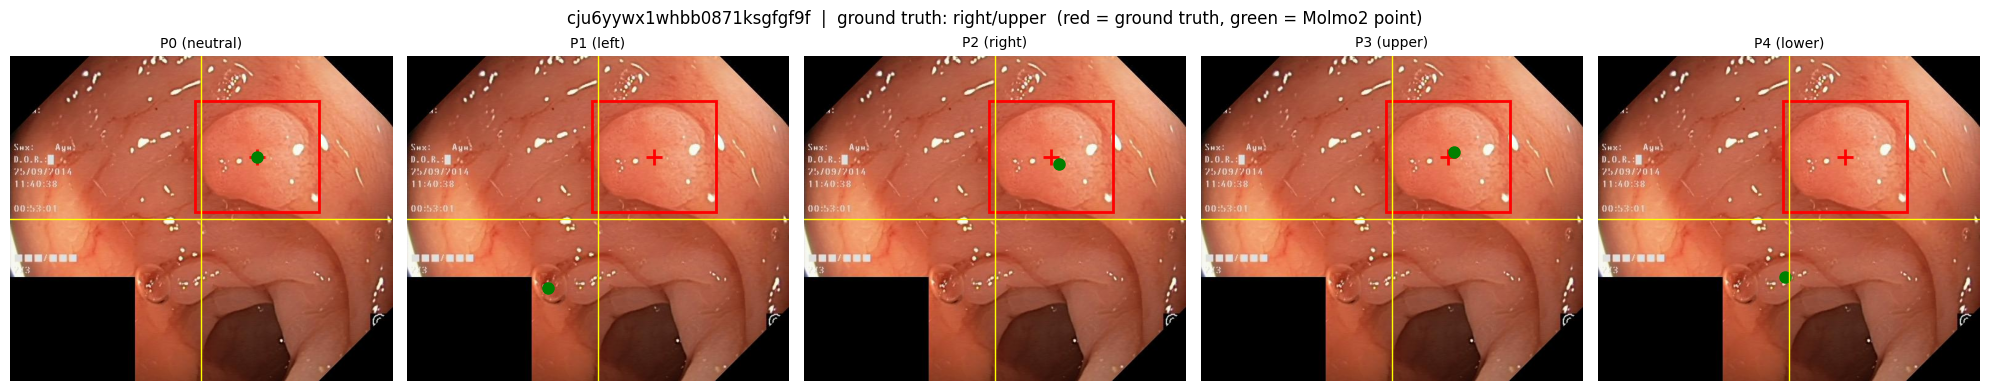

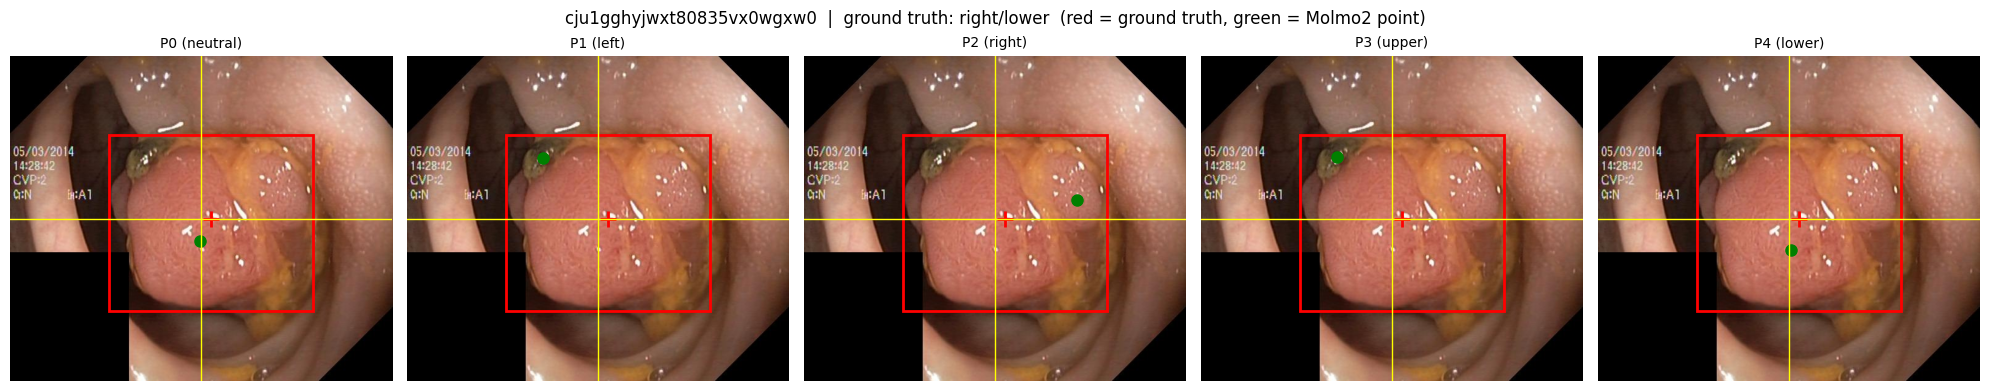

[ok] saved 50 comparison plots -> /content/drive/MyDrive/run_colab/results_kvasir_molmo2/visualizations
           molmo_correct_side  molmo_no_shift  molmo_dist_norm
prompt_id                                                     
P1                   0.720000        0.500000         0.148268
P2                   0.860000        0.600000         0.104427
P3                   0.840000        0.580000         0.115682
P4                   0.857143        0.612245         0.125355


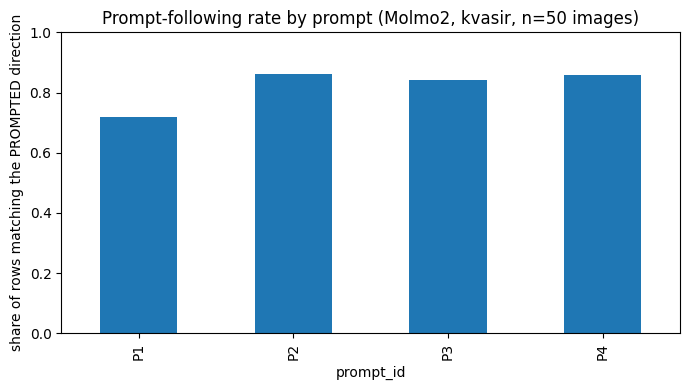

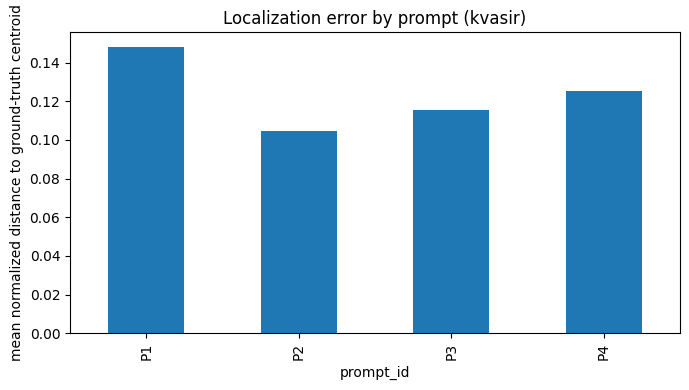

[ok] wrote summary -> /content/drive/MyDrive/run_colab/results_kvasir_molmo2/kvasir_molmo2_summary_by_prompt.csv
RQ2 (kvasir) -- prompt already matches ground truth (does wording alone still cause disagreement?):
           molmo_correct_side  molmo_dist_norm
prompt_id                                     
P1                   1.000000         0.044283
P2                   1.000000         0.069004
P3                   1.000000         0.061614
P4                   0.958333         0.059103

RQ3 (kvasir) -- prompt contradicts ground truth (a high correct_side rate here = model trusts the TEXT over the pixels):
           molmo_correct_side  molmo_dist_norm
prompt_id                                     
P1                   0.600000         0.192833
P2                   0.533333         0.187080
P3                   0.666667         0.174256
P4                   0.760000         0.188956

Processing dataset: isic
[ok] isic: loaded manifest with 250 rows, 50 images


Molmo2 inference (isic):   0%|          | 0/250 [00:00<?, ?it/s]

[ok] ran inference on 250 rows (0 rows failed to parse a point)
[ok] derived scoring columns computed
[ok] wrote 250 rows x 29 columns -> /content/drive/MyDrive/run_colab/results_isic_molmo2/isic_molmo2_results.csv


Rendering isic visualizations:   0%|          | 0/50 [00:00<?, ?it/s]

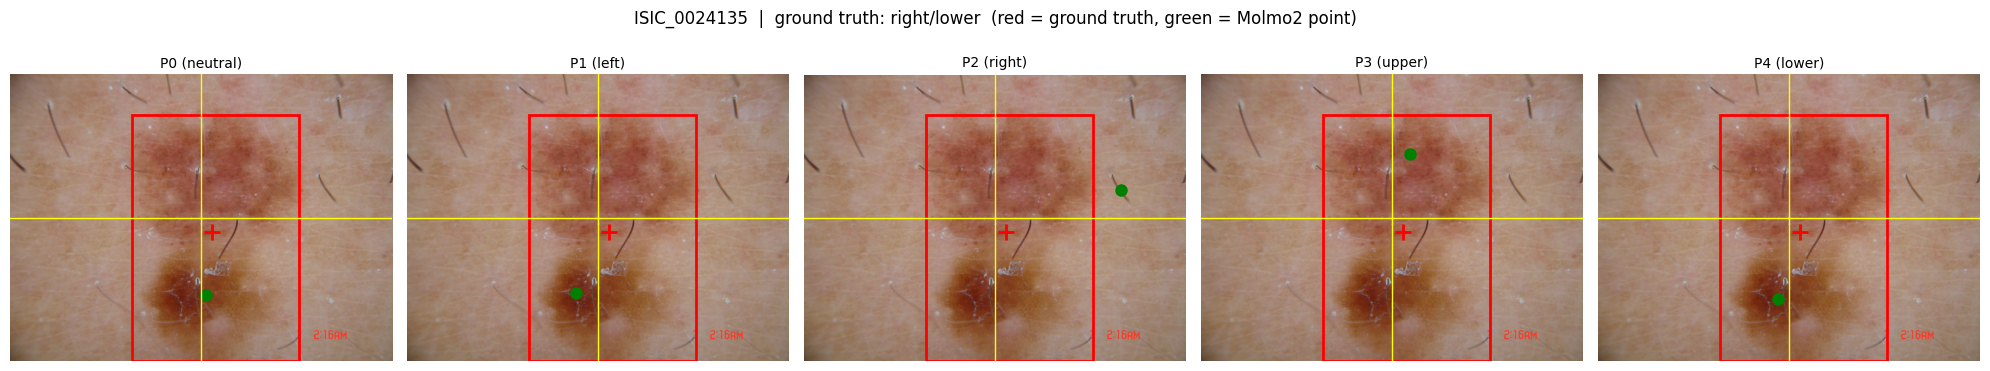

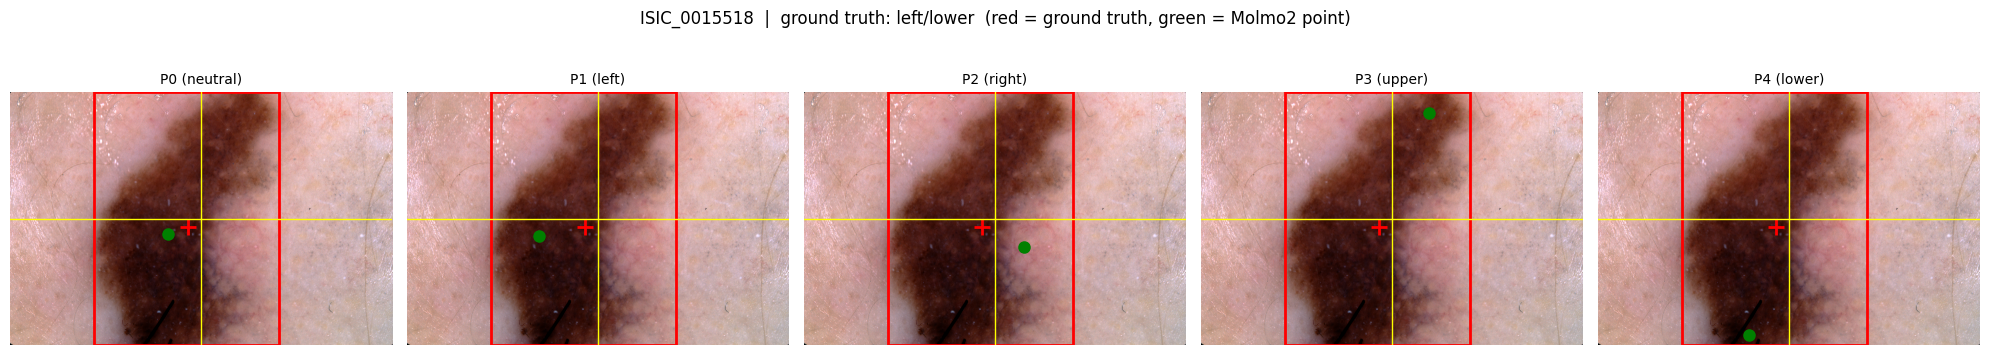

[ok] saved 50 comparison plots -> /content/drive/MyDrive/run_colab/results_isic_molmo2/visualizations
           molmo_correct_side  molmo_no_shift  molmo_dist_norm
prompt_id                                                     
P1                       0.94            0.16         0.187178
P2                       0.96            0.22         0.201318
P3                       0.92            0.10         0.202452
P4                       0.98            0.28         0.164579


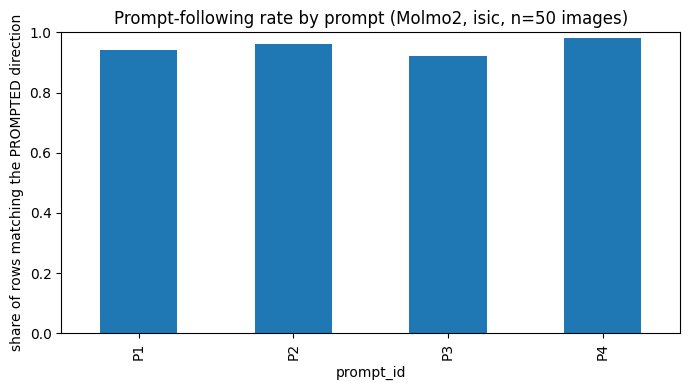

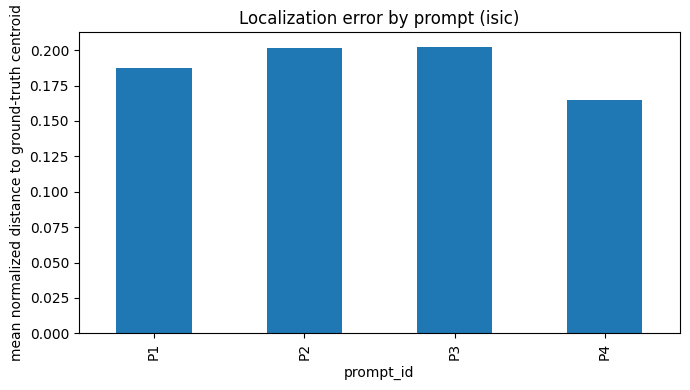

[ok] wrote summary -> /content/drive/MyDrive/run_colab/results_isic_molmo2/isic_molmo2_summary_by_prompt.csv
RQ2 (isic) -- prompt already matches ground truth (does wording alone still cause disagreement?):
           molmo_correct_side  molmo_dist_norm
prompt_id                                     
P1                       1.00         0.164460
P2                       1.00         0.165862
P3                       0.96         0.185792
P4                       1.00         0.161015

RQ3 (isic) -- prompt contradicts ground truth (a high correct_side rate here = model trusts the TEXT over the pixels):
           molmo_correct_side  molmo_dist_norm
prompt_id                                     
P1                       0.88         0.209895
P2                       0.92         0.236775
P3                       0.88         0.219112
P4                       0.96         0.168143

Processing dataset: lgg
[ok] lgg: loaded manifest with 250 rows, 50 images


Molmo2 inference (lgg):   0%|          | 0/250 [00:00<?, ?it/s]

[ok] ran inference on 250 rows (24 rows failed to parse a point)
[debug] raw text from up to 3 failed rows, to check the actual output format:
  [0] 'There are none.'
  [1] 'There are none.'
  [2] 'There are none.'
[ok] derived scoring columns computed
[ok] wrote 250 rows x 29 columns -> /content/drive/MyDrive/run_colab/results_lgg_molmo2/lgg_molmo2_results.csv


Rendering lgg visualizations:   0%|          | 0/50 [00:00<?, ?it/s]

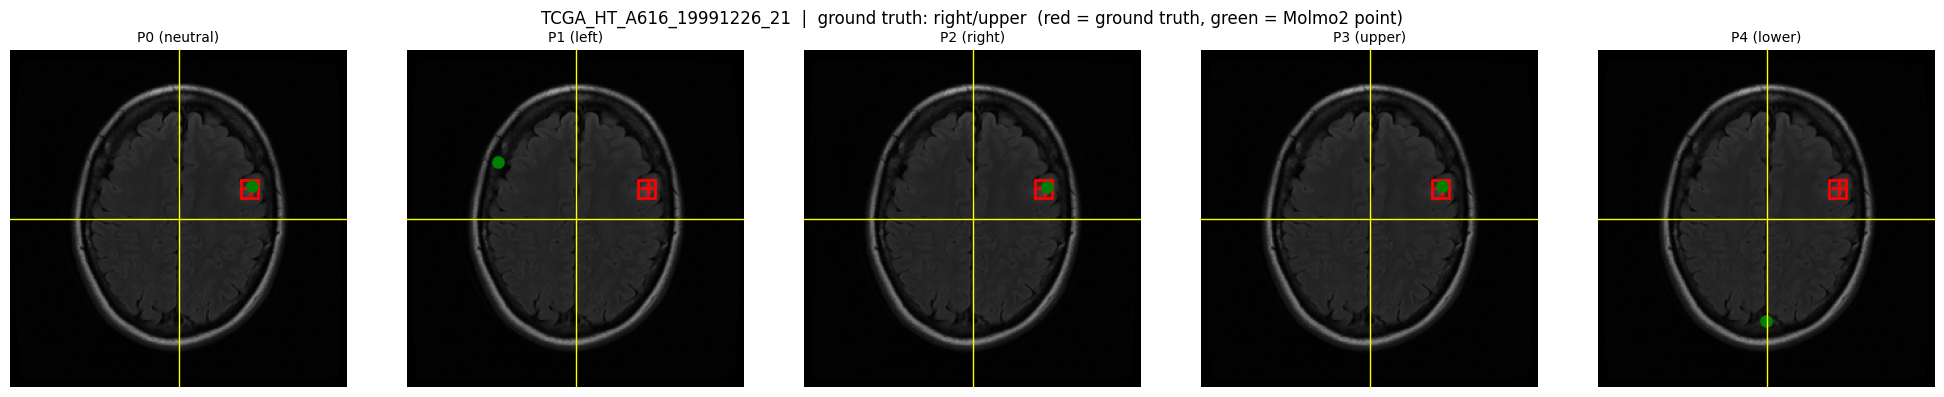

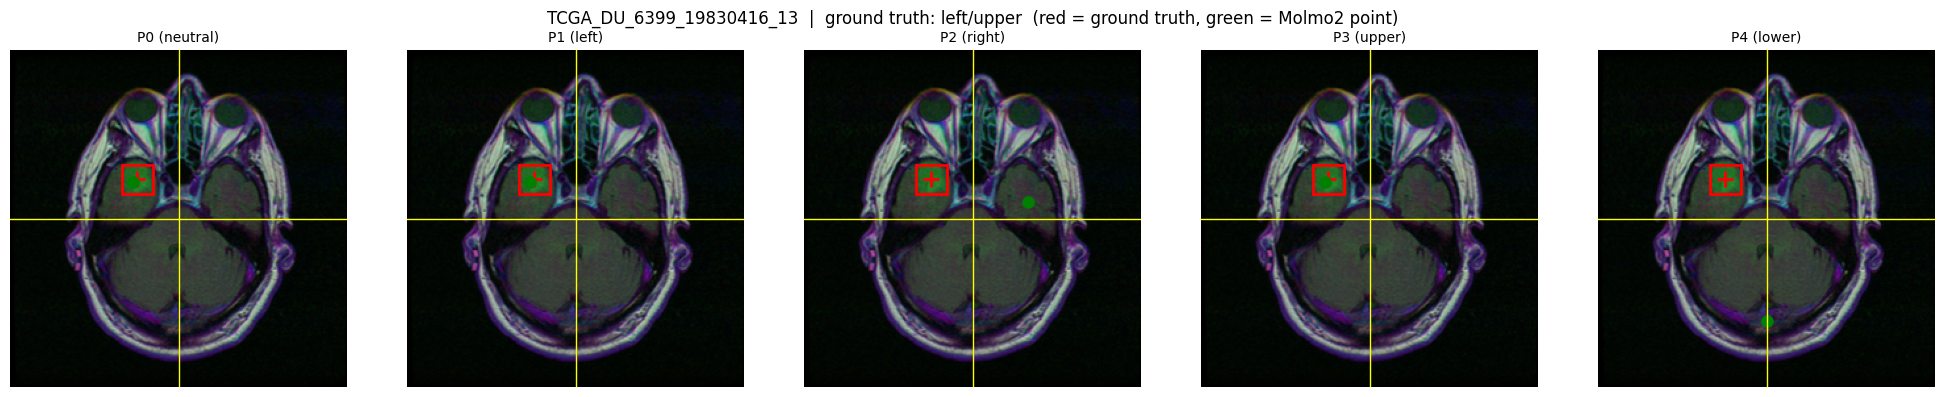

[ok] saved 50 comparison plots -> /content/drive/MyDrive/run_colab/results_lgg_molmo2/visualizations
           molmo_correct_side  molmo_no_shift  molmo_dist_norm
prompt_id                                                     
P1                   0.822222        0.717949         0.076769
P2                   0.913043        0.550000         0.106767
P3                   0.980000        0.590909         0.126884
P4                   1.000000        0.314286         0.204973


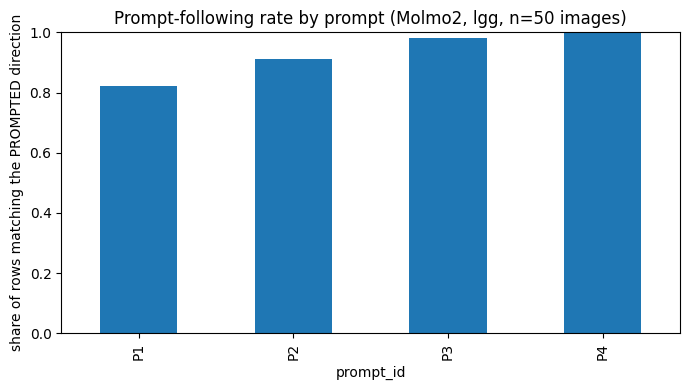

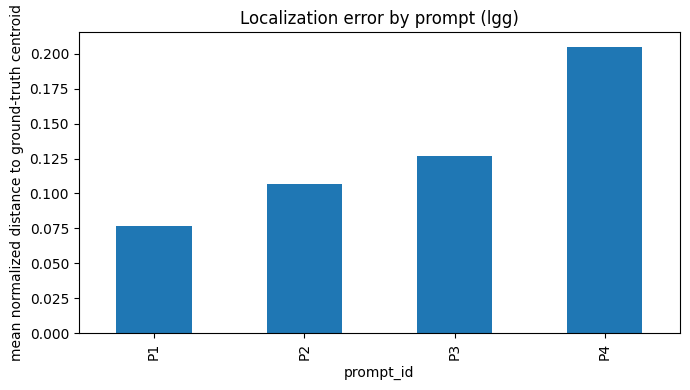

[ok] wrote summary -> /content/drive/MyDrive/run_colab/results_lgg_molmo2/lgg_molmo2_summary_by_prompt.csv
RQ2 (lgg) -- prompt already matches ground truth (does wording alone still cause disagreement?):
           molmo_correct_side  molmo_dist_norm
prompt_id                                     
P1                        1.0         0.020267
P2                        1.0         0.044440
P3                        1.0         0.064459
P4                        1.0         0.130954

RQ3 (lgg) -- prompt contradicts ground truth (a high correct_side rate here = model trusts the TEXT over the pixels):
           molmo_correct_side  molmo_dist_norm
prompt_id                                     
P1                   0.619048         0.141342
P2                   0.800000         0.187792
P3                   0.941176         0.248061
P4                   1.000000         0.257403

[ok] finished: ['kvasir', 'isic', 'lgg']


In [12]:
ALL_DATASETS = ["kvasir", "isic", "lgg"]

all_dfs = {}
for dataset_name in ALL_DATASETS:
    print(f"\n{'=' * 80}\nProcessing dataset: {dataset_name}\n{'=' * 80}")
    data_dir, out_dir, vis_dir = get_dataset_paths(dataset_name, f"results_{dataset_name}_molmo2")

    manifest_df = load_manifest(dataset_name, data_dir)
    result_df = run_molmo_inference(model, processor, DEVICE, manifest_df, data_dir, desc=f"Molmo2 inference ({dataset_name})")
    result_df = score_predictions(result_df, data_dir)
    save_results(result_df, out_dir, dataset_name)
    render_visualizations(result_df, data_dir, vis_dir, dataset_name, show_first=2)
    aggregate_and_report(result_df, out_dir, dataset_name)
    report_rq2_rq3(result_df, dataset_name)

    all_dfs[dataset_name] = result_df

print("\n[ok] finished:", list(all_dfs.keys()))